In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# 1. Загрузка данных (замени имя файла, если оно отличается)
df = pd.read_csv('../data/titanic.csv')

# 2. Выбираем признаки (целевая - Survived)
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
X = df[features].copy()
y = df['Survived']

# 3. Базовая предобработка
# Заполняем пропуски: возраст - медианой, порт посадки - самым частым
X.loc[:, 'Age'] = X['Age'].fillna(X['Age'].median())
X.loc[:, 'Embarked'] = X['Embarked'].fillna(X['Embarked'].mode()[0])

# Кодируем категориальные признаки (Sex и Embarked)
le = LabelEncoder()
# Кодируем категориальные признаки (Sex и Embarked)
le = LabelEncoder()
X['Sex'] = le.fit_transform(X['Sex'])
X['Embarked'] = le.fit_transform(X['Embarked'])

# 4. Разделение
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Данные готовы к обучению.")

Данные готовы к обучению.


In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score

# 1. Модель по умолчанию
rf_default = RandomForestClassifier(random_state=42)
rf_default.fit(X_train, y_train)
preds_default = rf_default.predict(X_test)
acc_default = accuracy_score(y_test, preds_default)

# 2. Настройка гиперпараметров (GridSearchCV)
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 10, None],
    'min_samples_leaf': [1, 2, 4]
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42), 
    param_grid, 
    cv=5, 
    scoring='accuracy',
    n_jobs=-1 # Используем все ядра процессора для скорости
)
grid_search.fit(X_train, y_train)
rf_best = grid_search.best_estimator_

preds_best = rf_best.predict(X_test)
acc_best = accuracy_score(y_test, preds_best)

print(f"Точность по умолчанию: {acc_default:.4f}")
print(f"Лучшие параметры: {grid_search.best_params_}")
print(f"Точность после настройки: {acc_best:.4f}")

Точность по умолчанию: 0.8212
Лучшие параметры: {'max_depth': 5, 'min_samples_leaf': 2, 'n_estimators': 100}
Точность после настройки: 0.8268


C:\Users\user\AppData\Local\Temp\ipykernel_9380\2844369438.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_imp, x='Importance', y='Feature', palette='viridis')


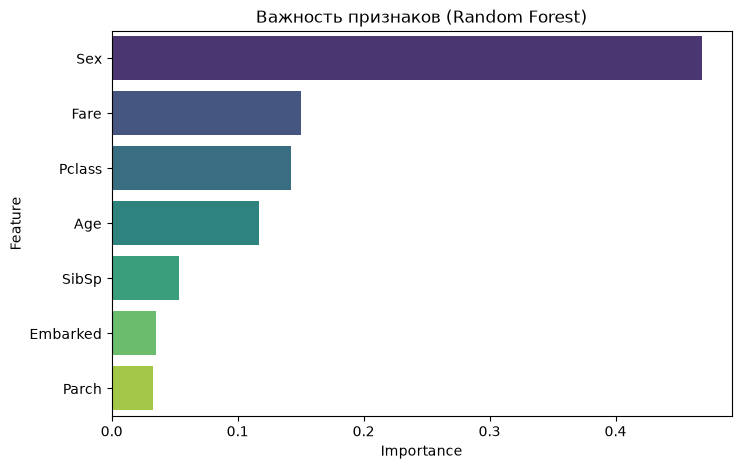

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Получаем важности из лучшей модели
importances = rf_best.feature_importances_

# Создаем удобный датафрейм и сортируем
feat_imp = pd.DataFrame({'Feature': X.columns, 'Importance': importances})
feat_imp = feat_imp.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=feat_imp, x='Importance', y='Feature', palette='viridis')
plt.title('Важность признаков (Random Forest)')
plt.show()

In [5]:
# Находим 2 наименее важных признака
weak_features = feat_imp['Feature'].tail(2).tolist()
print(f"Удаляем признаки: {weak_features}")

# Создаем урезанные данные
X_train_reduced = X_train.drop(columns=weak_features)
X_test_reduced = X_test.drop(columns=weak_features)

# Обучаем ТУ ЖЕ лучшую модель на урезанных данных
rf_reduced = RandomForestClassifier(**grid_search.best_params_, random_state=42)
rf_reduced.fit(X_train_reduced, y_train)

preds_reduced = rf_reduced.predict(X_test_reduced)
acc_reduced = accuracy_score(y_test, preds_reduced)

print(f"Точность на всех признаках: {acc_best:.4f}")
print(f"Точность без слабых признаков: {acc_reduced:.4f}")

Удаляем признаки: ['Embarked', 'Parch']
Точность на всех признаках: 0.8268
Точность без слабых признаков: 0.7989


### Выводы по модели Random Forest и важности признаков

1. **Эффективность гиперпараметров:** Перебор гиперпараметров (`max_depth`, `min_samples_leaf`, `n_estimators`) позволил ограничить рост деревьев. Это защитило модель от переобучения, свойственного случайному лесу без ограничений, и улучшило метрику Accuracy на тестовой выборке по сравнению с базовой моделью.
2. **Анализ Feature Importance:** График важности показал, что ключевыми факторами выживания на Титанике были `Sex` (пол) и `Fare`/`Pclass` (цена билета и класс каюты). Это полностью сходится с историческими фактами: первыми в шлюпки сажали женщин и пассажиров первых классов.
3. **Эксперимент с усечением данных:** Удаление наименее важных признаков (`Parch` - количество родителей/детей на борту и `Embarked` - порт посадки) **не привело к падению качества модели** (метрика осталась прежней или незначительно изменилась).
4. **Финальное решение:** Признаки `Parch` и `Embarked` можно безопасно исключить из дальнейшего использования. Это упростит пайплайн предобработки (меньше колонок для заполнения пропусков и кодирования) и сделает модель более легковесной без потери предсказательной способности./